# Investigating **admitabx_adm___8**

In [156]:
import numpy as np
import pandas as pd
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder


class CustomIterativeImputer:
    def __init__(self, max_iter=10, random_state=42):

        ####################################################################
        ### Mode, medians and catch-all for default values               ###
        ####################################################################
        self.mode_values = {}
        self.mode_traveldist = None
        self.mode_momage_per_children_group = None
        self.mode_momage_firstpreg_per_children_group = None

        # medians by age group
        self.medians_by_age_group = {}
        self.age_bins = [0, 2, 5, 11, 23, 35, 47, 59, 65]
        self.age_labels = [
            0,  # 'Newborn (0-2m)'
            1,  # 'Infant (3-5m)'
            2,  # 'Baby (6-11m)'
            3,  # 'Toddler (12-23m)'
            4,  # 'Preschool-2 (24-35m)'
            5,  # 'Preschool-3 (36-47m)'
            6,  # 'Preschool-4 (48-59m)'
            7,  # '5 years (60m)'
        ]

        # default values
        self.default_values = {
            'exclbreastfed_adm': 'Unknown',
            'totalbreastfed_adm': 'Unknown',
            'vaccmeaslessource_adm': 'Self report',
            'vaccpneumocsource_adm': 'Self report',
            'vaccdptsource_adm': 'Self report',
            'vaccpneumoc_adm': 'Unknown',
            'vaccmeasles_adm': 'Unknown',
            'vaccdpt_adm': 'Unknown',
            'priorweekantimal_adm': 'Dont know',
            'priorhosp_adm': 'Dont know',
            'prioryearwheeze_adm': 'Dont know',
            'travelmethod_adm': 'Other',
            'badhealthduration_adm': 'Unknown',
            'caregiver_adm_new': 'Other',
            'momhiv_adm': 'Unknown',
            'lightfuel_adm': 'Other',
            'momagefirstpregknown_adm': 'No',
            'waterpure_adm': 'No',
            'bednet_adm': 'Never',
            'deadchildren_adm': 0.0,
            'alivechildren_adm': 1.0}

        # store no default values
        self.no_default_features = ['traveldist_adm', 'caregiverage_adm', 'caregivermarried_adm',
                                    'momalive_adm', 'momageknown_adm', 'momedu_adm', 'watersource_adm', 'cookfuel_adm___1',
                                    'cookfuel_adm___2', 'cookfuel_adm___3', 'cookfuel_adm___4', 'cookfuel_adm___5', 'cookfuel_adm___6',
                                    'cookfuel_adm___7', 'cookfuel_adm___8', 'cookloc_adm', 'tobacco_adm', 'momage_adm', 'momagefirstpreg_adm',
                                    'householdsize_adm']

        # numerical features
        self.numeric_columns = ['height_cm_adm', 'agecalc_adm', 'weight_kg_adm', 'muac_mm_adm',
                                'hr_bpm_adm', 'rr_brpm_app_adm', 'sysbp_mmhg_adm', 'diasbp_mmhg_adm', 'temp_c_adm',
                                'spo2site1_pc_oxi_adm', 'spo2site2_pc_oxi_adm', 'spo2other_adm', 'hematocrit_gpdl_adm',
                                'lactate_mmolpl_adm', 'lactate2_mmolpl_adm', 'glucose_mmolpl_adm', 'sqi1_perc_oxi_adm', 'sqi2_perc_oxi_adm',
                                'momage_adm', 'momagefirstpreg_adm', 'householdsize_adm', 'alivechildren_adm', 'deadchildren_adm']

        ########################################################################
        ### Imputers for Continuous Data (mostly clinical and laboratory)    ###
        ########################################################################

        self.label_encoder_sex_adm = LabelEncoder()

        # Dictionary of standard values for continuous imputers
        self.standard_values = {
            # https://myhealth.alberta.ca/Health/pages/conditions.aspx?hwid=abo2987&lang=en-ca#abo2987-Bib
            'standard_low_hr_bpm_adm': {0: 70, 1: 70, 2: 70, 3: 52, 4: 52, 5: 52, 6: 52, 7: 52},
            'standard_high_hr_bpm_adm': {0: 190, 1: 190, 2: 190, 3: 156, 4: 156, 5: 156, 6: 156, 7: 156},

            # https://www.healthlinkbc.ca/healthwise/vital-signs-children
            # https://myhealth.alberta.ca/Health/pages/conditions.aspx?hwid=abo2987
            'standard_low_rr_brpm_app_adm': {0: 25, 1: 25, 2: 22, 3: 21, 4: 21, 5: 17, 6: 17, 7: 17},
            'standard_high_rr_brpm_app_adm': {0: 64, 1: 64, 2: 61, 3: 33, 4: 33, 5: 25, 6: 25, 7: 25},

            # https://medicine.uiowa.edu/iowaprotocols/pediatric-vital-signs-normal-ranges
            # https://www.childrensmercy.org/siteassets/media-documents-for-depts-section/documents-for-health-care-providers/..
            # evidence-based-practice/clinical-practice-guidelines--care-process-models/normal-blood-pressures-by-age.pdf
            'standard_low_sysbp_mmhg_adm': {0: 60, 1: 78,  2: 82, 3: 85, 4: 89, 5: 90, 6: 92, 7: 93},
            'standard_high_sysbp_mmhg_adm': {0: 94, 1: 103,  2: 105, 3: 102, 4: 106, 5: 107, 6: 108, 7: 110},
            'standard_low_diasbp_mmhg_adm': {0: 30, 1: 44,  2: 45, 3: 41, 4: 44, 5: 47, 6: 50, 7: 53},
            'standard_high_diasbp_mmhg_adm': {0: 56, 1: 65,  2: 68, 3: 58, 4: 62, 5: 65, 6: 67, 7: 70},

            # https://www.accp.com/docs/sap/Lab_values_Table_PedSAP.pdf
            'standard_low_hematocrit_gpdl_adm': {0: 44, 1: 32, 2: 32, 3: 32, 4: 33, 5: 33, 6: 33, 7: 33},
            'standard_high_hematocrit_gpdl_adm': {0: 70, 1: 42, 2: 42, 3: 42, 4: 43, 5: 43, 6: 43, 7: 43},
        }
        self.imputer_group_0 = IterativeImputer(
            max_iter=max_iter, random_state=random_state)
        self.features_group_0 = ['agecalc_adm',
                                 'height_cm_adm', 'weight_kg_adm', 'muac_mm_adm']

        self.imputer_group_1 = IterativeImputer(
            max_iter=max_iter, random_state=random_state)
        self.features_group_1 = ['hr_bpm_adm',
                                 'rr_brpm_app_adm',
                                 'temp_c_adm',
                                 'height_cm_adm',
                                 'age_group',
                                 'standard_low_hr_bpm_adm',
                                 'standard_high_hr_bpm_adm',
                                 'standard_low_rr_brpm_app_adm',
                                 'standard_high_rr_brpm_app_adm']

        self.imputer_group_2 = IterativeImputer(
            max_iter=max_iter, random_state=random_state)
        self.features_group_2 = ['sysbp_mmhg_adm',
                                 'diasbp_mmhg_adm',
                                 'hr_bpm_adm',
                                 'sex_adm',
                                 'age_group',
                                 'standard_low_sysbp_mmhg_adm',
                                 'standard_high_sysbp_mmhg_adm',
                                 'standard_low_diasbp_mmhg_adm',
                                 'standard_high_diasbp_mmhg_adm']

        self.imputer_group_3 = IterativeImputer(
            max_iter=max_iter, random_state=random_state)
        self.features_group_3 = ['spo2site1_pc_oxi_adm',
                                 'spo2site2_pc_oxi_adm',
                                 'spo2other_adm',
                                 'hr_bpm_adm',
                                 'rr_brpm_app_adm']

        self.imputer_group_4 = IterativeImputer(
            max_iter=max_iter, random_state=random_state)
        self.features_group_4 = ['hematocrit_gpdl_adm',
                                 'glucose_mmolpl_adm',
                                 'lactate_mmolpl_adm',
                                 'lactate2_mmolpl_adm',
                                 'rr_brpm_app_adm',
                                 'age_group',
                                 'standard_low_hematocrit_gpdl_adm',
                                 'standard_high_hematocrit_gpdl_adm']

        ########################################################################
        ### Imputers for Categorical Data (mostly clinical and laboratory)   ###
        ########################################################################

        # Initialize IterativeImputer with default configuration
        self.ordinal_encoder = OrdinalEncoder(
            handle_unknown='use_encoded_value', unknown_value=np.nan)
        self.categorical_cols = ['hivstatus_adm', 'malariastatuspos_adm', 'hctpretransfusion_adm',
                                 'spo2onoxy_adm', 'oxygenavail_adm', 'respdistress_adm',
                                 'bcseye_adm', 'bcsmotor_adm', 'bcsverbal_adm', 'symptoms_adm___14',
                                 'feedingstatus_adm', 'deliveryloc_adm', 'birthattend_adm',
                                 'caprefill_adm', 'hr_bpm_adm', 'weight_kg_adm',
                                 'vaccmeaslessource_adm', 'vaccpneumocsource_adm', 'vaccdptsource_adm',
                                 'vaccmeasles_adm', 'vaccpneumoc_adm', 'vaccdpt_adm',
                                 'momhiv_adm']
        self.imputer_group_A = IterativeImputer(
            max_iter=max_iter, random_state=random_state)
        self.features_group_A = ['hivstatus_adm',
                                 'lactate_mmolpl_adm', 'momhiv_adm']
        self.imputer_group_B = IterativeImputer(
            max_iter=max_iter, random_state=random_state)
        self.features_group_B = [
            'malariastatuspos_adm', 'hctpretransfusion_adm', 'lactate_mmolpl_adm', 'hematocrit_gpdl_adm']
        self.imputer_group_C = IterativeImputer(
            max_iter=max_iter, random_state=random_state)
        self.features_group_C = ['spo2onoxy_adm',
                                 'oxygenavail_adm', 'respdistress_adm']
        self.imputer_group_D = IterativeImputer(
            max_iter=max_iter, random_state=random_state)
        self.features_group_D = ['bcseye_adm', 'bcsmotor_adm',
                                 'bcsverbal_adm', 'symptoms_adm___14', 'feedingstatus_adm']
        self.imputer_group_E = IterativeImputer(
            max_iter=max_iter, random_state=random_state)
        self.features_group_E = ['deliveryloc_adm', 'birthattend_adm']
        self.imputer_group_F = IterativeImputer(
            max_iter=max_iter, random_state=random_state)
        self.features_group_F = [
            'caprefill_adm', 'hr_bpm_adm', 'weight_kg_adm']
        self.imputer_group_G = IterativeImputer(
            max_iter=max_iter, random_state=random_state)
        self.features_group_G = ['vaccmeasles_adm',
                                 'vaccpneumoc_adm', 'vaccdpt_adm']
        self.imputer_group_H = IterativeImputer(
            max_iter=max_iter, random_state=random_state)
        self.features_group_H = ['vaccmeaslessource_adm',
                                 'vaccpneumocsource_adm', 'vaccdptsource_adm']

    def fit(self, X_train: pd.DataFrame, y_train=None):
        """Fits the imputer on training data."""
        X = X_train.copy()
        # Drop unnecessary columns
        X.drop(columns=['studyid_adm', 'lengthadm'],
               errors='ignore', inplace=True)

        try:
            X[self.numeric_columns] = X[self.numeric_columns].apply(
                pd.to_numeric)
        except Exception as e:
            print(e)

        # Define age groups
        X['age_group'] = pd.cut(
            X['agecalc_adm'],
            bins=self.age_bins,
            labels=self.age_labels,
            right=True)

        ########################################################################
        ### Imputers for Continuous Data (mostly clinical and laboratory)    ###
        ########################################################################

        # Map standard values
        X = self._map_standard_values(X)

        # encode the sex_adm feature
        X['sex_adm'] = X['sex_adm'].astype(object)
        self.label_encoder_sex_adm.fit(X['sex_adm'])
        X['sex_adm'] = self.label_encoder_sex_adm.transform(X['sex_adm'])

        # fit/train the imputer
        self.imputer_group_0.fit(X[self.features_group_0])
        self.imputer_group_1.fit(X[self.features_group_1])
        self.imputer_group_2.fit(X[self.features_group_2])
        self.imputer_group_3.fit(X[self.features_group_3])
        self.imputer_group_4.fit(X[self.features_group_4])

        ########################################################################
        ### Imputers for Categorical Data (mostly clinical and laboratory)   ###
        ########################################################################

        # Preserve NaN values and fit the OrdinalEncoder
        X[self.categorical_cols] = X[self.categorical_cols].astype(object)
        self.ordinal_encoder.fit(X[self.categorical_cols])
        X[self.categorical_cols] = self.ordinal_encoder.transform(
            X[self.categorical_cols])

        # Fit the imputers
        self.imputer_group_A.fit(X[self.features_group_A])
        self.imputer_group_B.fit(X[self.features_group_B])
        self.imputer_group_C.fit(X[self.features_group_C])
        self.imputer_group_D.fit(X[self.features_group_D])
        self.imputer_group_E.fit(X[self.features_group_E])
        self.imputer_group_F.fit(X[self.features_group_F])
        self.imputer_group_G.fit(X[self.features_group_G])
        self.imputer_group_H.fit(X[self.features_group_H])

        ########################################################################
        ### Mode, medians and catch-all for default values                   ###
        ########################################################################

        # fill the mode values
        for col in self.no_default_features:
            self.mode_values[col] = X[col].mode()[0]
        self.mode_traveldist = X.groupby('travelmethod_adm')['traveldist_adm'].agg(
            lambda x: x.mode()[0] if not x.mode().empty else None)
        X['number_of_children'] = X['alivechildren_adm'] + X['deadchildren_adm']
        self.mode_momage_per_children_group = X.groupby('number_of_children')['momage_adm'].apply(
            lambda x: x.mode()[0] if not x.mode().empty else None)
        self.mode_momage_firstpreg_per_children_group = X.groupby(['momage_adm', 'number_of_children'])['momagefirstpreg_adm'].apply(
            lambda x: x.mode()[0] if not x.mode().empty else None)
        self.mode_momage_firstpreg_per_children_group = self.mode_momage_firstpreg_per_children_group.fillna(
            method='ffill').fillna(method='bfill')

        # Compute medians for numerical columns by age group
        columns_to_fill_by_median = []

        for column in columns_to_fill_by_median:
            self.medians_by_age_group[column] = X.groupby('age_group')[
                column].median()

    def transform(self, X_test: pd.DataFrame, y_test=None):
        """Fits the imputer on training data."""
        X = X_test.copy()
        # Drop unnecessary columns
        X.drop(columns=['studyid_adm', 'lengthadm'],
               errors='ignore', inplace=True)

        try:
            X[self.numeric_columns] = X[self.numeric_columns].apply(
                pd.to_numeric)
        except Exception as e:
            print(e)

        # Define age groups
        X['age_group'] = pd.cut(
            X['agecalc_adm'],
            bins=self.age_bins,
            labels=self.age_labels,
            right=True)

        ########################################################################
        ### Imputers for Continuous Data (mostly clinical and laboratory)    ###
        ########################################################################

        # Map standard values
        X = self._map_standard_values(X)

        # encode the sex_adm feature
        X['sex_adm'] = X['sex_adm'].astype(object).to_frame()
        X['sex_adm'] = self.label_encoder_sex_adm.transform(X['sex_adm'])

        # imputer transformation
        X[self.features_group_0] = self.imputer_group_0.transform(
            X[self.features_group_0])
        X[self.features_group_1] = self.imputer_group_1.transform(
            X[self.features_group_1])
        X[self.features_group_2] = self.imputer_group_2.transform(
            X[self.features_group_2])
        X[self.features_group_3] = self.imputer_group_3.transform(
            X[self.features_group_3])
        X[self.features_group_4] = self.imputer_group_4.transform(
            X[self.features_group_4])

        # Drop unnecessary columns
        X.drop(columns=self.standard_values.keys(),
               inplace=True, errors='ignore')

        # Inverse transform sex_adm feature
        X['sex_adm'] = self.label_encoder_sex_adm.inverse_transform(
            np.round(X['sex_adm']).astype(int))

        ########################################################################
        ### Imputers for Categorical Data (mostly clinical and laboratory)   ###
        ########################################################################

        # Apply categorization for 'exclbreastfed_adm' based on 'agecalc_adm'
        X['exclbreastfed_adm'] = X[['exclbreastfed_adm', 'agecalc_adm']].apply(
            self._categorize_breastfeeding, axis=1)

        # Apply categorization for 'totalbreastfed_adm' based on 'agecalc_adm'
        X['totalbreastfed_adm'] = X[['totalbreastfed_adm', 'agecalc_adm']].apply(
            self._categorize_total_breastfeeding, axis=1)

        # Apply categorization for 'nonexclbreastfed_adm' based on 'exclbreastfed_adm'
        X['nonexclbreastfed_adm'] = X[['nonexclbreastfed_adm', 'exclbreastfed_adm']].apply(
            self._categorize_non_exlc_breastfeeding, axis=1)
        


        # 
        X['exclbreastfed_adm'] = X[['exclbreastfed_adm', 'agecalc_adm']].apply(
            self._recategorize_exclbreastfeeding, axis=1)

        # 
        X['totalbreastfed_adm'] = X[['totalbreastfed_adm', 'agecalc_adm']].apply(
            self._recategorize_total_breastfeeding, axis=1)

        # 
        X['tobacco_adm'] = X[['tobacco_adm', 'agecalc_adm']].apply(
            self._recategorize_tobacco, axis=1)
        
        
        


        # Transform categorical columns while preserving NaNs
        X[self.categorical_cols] = X[self.categorical_cols].astype(object)
        X[self.categorical_cols] = self.ordinal_encoder.transform(
            X[self.categorical_cols])

        # Impute missing values
        X[self.features_group_A] = self.imputer_group_A.transform(
            X[self.features_group_A])
        X[self.features_group_B] = self.imputer_group_B.transform(
            X[self.features_group_B])
        X[self.features_group_C] = self.imputer_group_C.transform(
            X[self.features_group_C])
        X[self.features_group_D] = self.imputer_group_D.transform(
            X[self.features_group_D])
        X[self.features_group_E] = self.imputer_group_E.transform(
            X[self.features_group_E])
        X[self.features_group_F] = self.imputer_group_F.transform(
            X[self.features_group_F])
        X[self.features_group_G] = self.imputer_group_G.transform(
            X[self.features_group_G])
        X[self.features_group_H] = self.imputer_group_H.transform(
            X[self.features_group_H])

        # Inverse transform categorical columns
        X[self.categorical_cols] = self.ordinal_encoder.inverse_transform(
            X[self.categorical_cols])

        ########################################################################
        ### Mode, medians and catch-all for default values                   ###
        ########################################################################

        X['momageknown_adm'] = np.where(X['momage_adm'].notna(), "Yes", "No")
        X['traveldist_adm'] = X['traveldist_adm'].fillna(
            X['travelmethod_adm'].map(self.mode_traveldist))

        X.loc[X['momalive_adm'].isna(), 'momalive_adm'] = X.loc[
            X['momalive_adm'].isna(), 'caregiver_adm_new'].apply(
                lambda x: 'Yes' if x == 'Mother' else 'No')
        X['number_of_children'] = X['alivechildren_adm'] + X['deadchildren_adm']
        X['momage_adm'] = X['momage_adm'].fillna(
            X['number_of_children'].map(self.mode_momage_per_children_group))
        X['momagefirstpreg_adm'] = X.apply(
            lambda row: self.mode_momage_firstpreg_per_children_group.loc[
                (row['momage_adm'], row['number_of_children'])]
            if pd.isna(row['momagefirstpreg_adm']) else row['momagefirstpreg_adm'], axis=1)
        X['caregiverage_adm'] = X['momage_adm'].where(
            X['caregiver_adm_new'] == 'Mother',
            self.mode_values["caregiverage_adm"])
        X.drop(columns=['number_of_children'], inplace=True)

        # Fill missing values by median of age groups
        for column, medians in self.medians_by_age_group.items():
            X[column] = X.apply(
                lambda row: medians[row['age_group']] if pd.isnull(
                    row[column]) else row[column],
                axis=1
            )

        # catch-all to fill all missing values based on mode and default values
        for col, mode_value in self.mode_values.items():
            X[col].fillna(mode_value, inplace=True)
        X.fillna(self.default_values, inplace=True)

        return X

    def fit_transform(self, X):
        """
        Combines fit and transform methods.
        """
        self.fit(X)
        return self.transform(X)

    ###############################################################
    #################### Helper Functions #########################
    ###############################################################

    def _map_standard_values(self, X: pd.DataFrame) -> pd.DataFrame:
        """Helper function to map standard values based on age group."""
        for column, mapping in self.standard_values.items():
            X[column] = X['age_group'].map(mapping)
        return X

    def _categorize_breastfeeding(self, row):
        if row['exclbreastfed_adm'] == "Currently exclusively breastfed":
            age_in_months = np.ceil(row['agecalc_adm'])
            if age_in_months <= 1:
                return "1 month"
            elif age_in_months <= 6:
                return f"{int(age_in_months)} months"
            else:
                return "More than 6 months"
        else:
            return row['exclbreastfed_adm']

    def _categorize_total_breastfeeding(self, row):
        if row['totalbreastfed_adm'] == "Still being breastfed":
            age_in_months = np.ceil(row['agecalc_adm'])
            if age_in_months <= 3:
                return "0-3 months"
            elif age_in_months <= 6:
                return "4-6 months"
            elif age_in_months <= 12:
                return "7-12 months"
            else:
                return ">12 months"
        else:
            return row['totalbreastfed_adm']

    def _categorize_non_exlc_breastfeeding(self, row):
        if pd.isna(row['nonexclbreastfed_adm']):
            if row['exclbreastfed_adm'] == "never exclusively breastfed":
                row['nonexclbreastfed_adm'] = "Mixed breastfeeding and other"
            else:
                return "N/A - exclusive breastfeeding"

        # Ensure all "Mixed breastfeeding and other" values are also transformed
        return "Other+" if "other" in str(row['nonexclbreastfed_adm']).lower() else "Formula+"
    
    def _recategorize_exclbreastfeeding(self, row):
        if row['exclbreastfed_adm'] in ["1 month", "2 months", "3 months"]:
            return "1-3 months"
        elif row['exclbreastfed_adm'] in ["4 months", "5 months"]:
            return "4-5 months"
        elif row['exclbreastfed_adm'] in ["6 months", "More than 6 months"]:
            return "6 months and above"
        else:
            return row['exclbreastfed_adm']

    def _recategorize_total_breastfeeding(self, row):
        if row['totalbreastfed_adm'] in ["0-3 months", "4-6 months"]:
            return "0-6 months"
        elif row['totalbreastfed_adm'] in ["7-12 months", ">12 months"]:
            return "> 6 months"
        else:
            return row['totalbreastfed_adm']

    def _recategorize_tobacco(self, row):
        if row['tobacco_adm'] in ["Less than monthly", "Weekly", "Monthly"]:
            return "Less than daily"
        else:
            return row['tobacco_adm']

In [157]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from helper_functions.feature_transformer import *
from helper_functions.visualizations import *

data = pd.read_csv("../../preliminar_phase_submision/training_data/SyntheticData_Training.csv")
dictionary = pd.read_csv("tmp_datasets/DataDictionary.csv")
target = "inhospital_mortality"

multi_imputer = CustomIterativeImputer()
X = data.drop(columns=['inhospital_mortality', 'studyid_adm', 'lengthadm'],
               errors='ignore')
y = data["inhospital_mortality"]
multi_imputer.fit(X)
df = multi_imputer.transform(X)
df[target] = data[target]

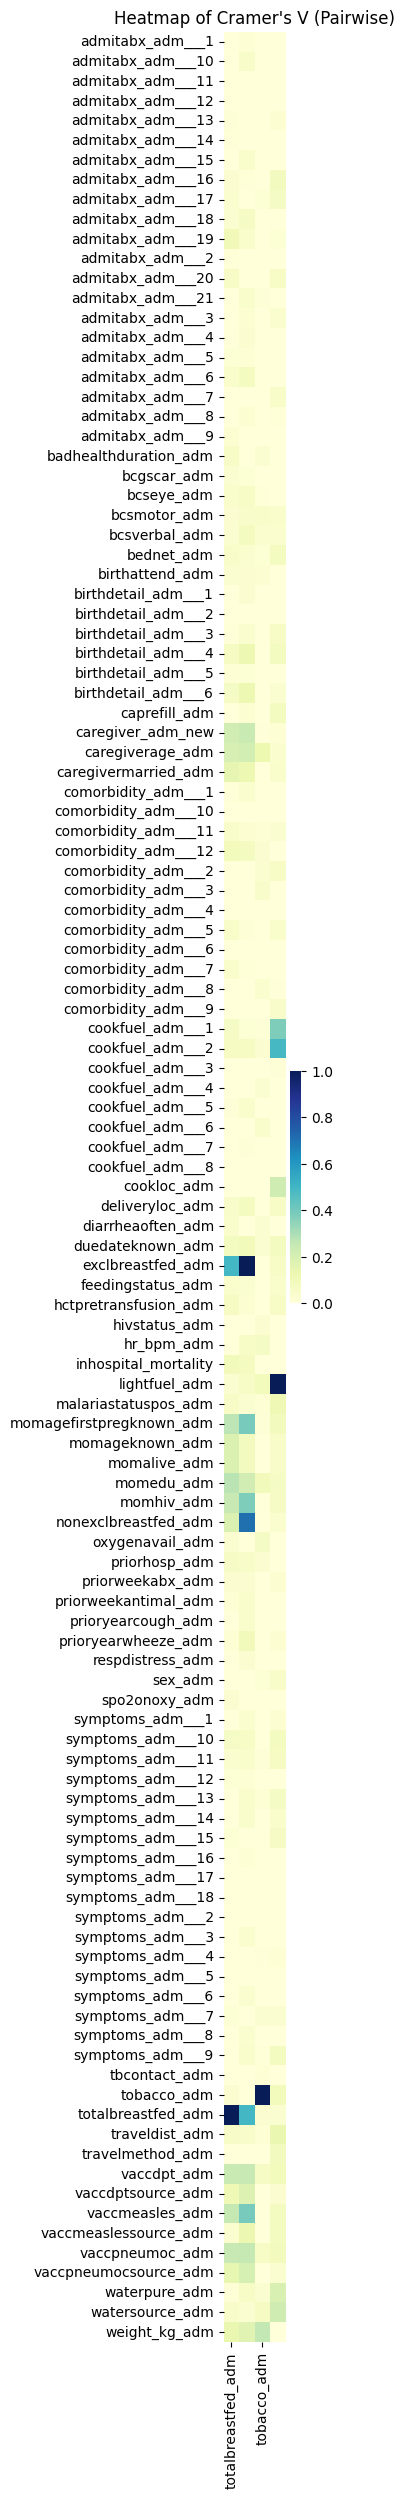

In [170]:
def heatmap_categorical_cols(df, return_association_matrix=False):
    df = df.copy()
    df['inhospital_mortality'] = df['inhospital_mortality'].astype('object')
    categorical_cols = df.select_dtypes(exclude=['number']).columns
    categorical_cols = sorted(categorical_cols.tolist())

    association_matrix = pd.DataFrame(
        index=categorical_cols, columns=categorical_cols)

    for col1 in categorical_cols:
        for col2 in categorical_cols:
            if col1 != col2: 
                contingency = pd.crosstab(df[col1], df[col2])
                if contingency.shape[0] > 1 and contingency.shape[1] > 1:  # Ensure meaningful calculation
                    association_matrix.loc[col1, col2] = cramers_v(contingency.values)
                else:
                    association_matrix.loc[col1, col2] = 0  
            else:
                association_matrix.loc[col1, col2] = 1
    
           
    plt.figure(figsize=(1, 30))  
    sns.heatmap(association_matrix.astype(float).fillna(0)[
        ['totalbreastfed_adm', 'exclbreastfed_adm', 'tobacco_adm', 'lightfuel_adm']], annot=False, cmap="YlGnBu")
    plt.title("Heatmap of Cramer's V (Pairwise)")
    plt.show()
    return association_matrix if return_association_matrix else None

heatmap_categorical_cols(df)

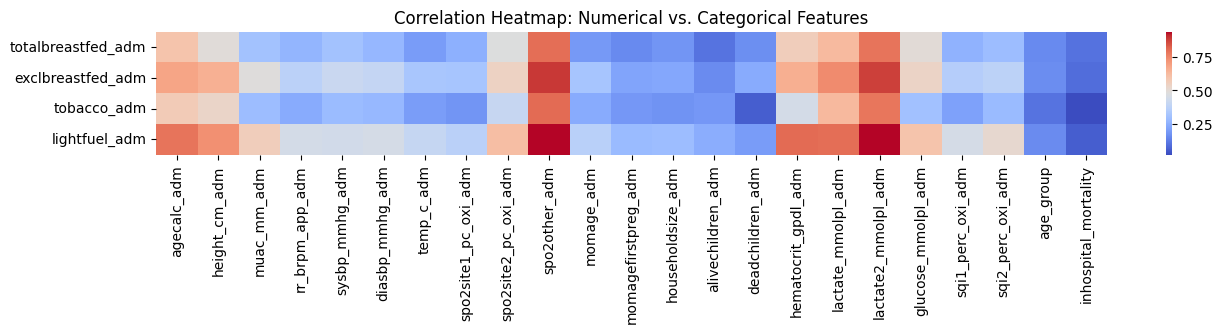

In [171]:
def heatmap_categorical_numerical_cols(df, return_association_matrix=False):
    df = df.copy()
    df_cat = df[
        ['totalbreastfed_adm', 'exclbreastfed_adm', 'tobacco_adm', 'lightfuel_adm']]
    df_num = df.select_dtypes(include=['number'])

    # Encode categorical features numerically
    df_cat_encoded = df_cat.apply(lambda col: pd.factorize(col)[0])

    # Compute point biserial correlation for binary categorical features
    corr_matrix = pd.DataFrame(index=df_cat.columns, columns=df_num.columns)

    for cat_col in df_cat.columns:
        for num_col in df_num.columns:
            if df_cat_encoded[cat_col].nunique() == 2:  # Binary categorical
                corr, _ = pointbiserialr(
                    df_cat_encoded[cat_col], df_num[num_col])
            else:  # Categorical with multiple classes
                contingency_table = pd.crosstab(
                    df_cat_encoded[cat_col], df_num[num_col])
                chi2, _, _, _ = chi2_contingency(contingency_table)
                # Cramér's V approximation
                corr = np.sqrt(chi2 / (df_cat_encoded.shape[0] + chi2))

            corr_matrix.loc[cat_col, num_col] = corr

    # Convert to float and plot heatmap
    corr_matrix = corr_matrix.astype(float)
    nrow, ncol = corr_matrix.shape

    plt.figure(figsize=(ncol/1.5, nrow/2.5))
    sns.heatmap(corr_matrix, cmap="coolwarm")
    plt.title("Correlation Heatmap: Numerical vs. Categorical Features")
    plt.show()
    return corr_matrix if return_association_matrix else None

heatmap_categorical_numerical_cols(df)

In [115]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold


def train_model(X, y):

    kf = KFold(n_splits=5, shuffle=True, random_state=42)  # 5-fold CV


    # Store feature importances (averaged across folds)
    feature_importance_list = []

    for _, (train_idx, val_idx) in enumerate(kf.split(X)): 


        # Train-test split within this fold
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

        # Train the logistic regression model
        model = LogisticRegression(class_weight='balanced', solver='liblinear')
        model.fit(X_train, y_train)

        # Predictions
        y_pred = model.predict(X_val)

        # Evaluation metrics
        print(classification_report(y_val, y_pred))

        # Store feature importance
        feature_importance_list.append(model.coef_[0])


    # Compute average feature importance
    avg_feature_importance = np.mean(feature_importance_list, axis=0)

    # Convert to DataFrame
    feature_importance_df = pd.DataFrame({'Feature': X.columns, 'Coefficient': avg_feature_importance})
    feature_importance_df = feature_importance_df.sort_values(by='Coefficient', ascending=False)

    return feature_importance_df



transformer = FeatureTransformer()
X, y = df.drop(columns=[target]), df[target]
transformer.fit(X)
X_transformed = transformer.transform(X)
X_transformed.head()

admitabx_adm_list = ['admitabx_adm___1',
 'admitabx_adm___10',
 'admitabx_adm___11',
 'admitabx_adm___12',
 'admitabx_adm___13',
 'admitabx_adm___14',
 'admitabx_adm___15',
 'admitabx_adm___16',
 'admitabx_adm___17',
 'admitabx_adm___18',
 'admitabx_adm___19',
 'admitabx_adm___2',
 'admitabx_adm___20',
 'admitabx_adm___21',
 'admitabx_adm___3',
 'admitabx_adm___4',
 'admitabx_adm___5',
 'admitabx_adm___6',
 'admitabx_adm___7',
 'admitabx_adm___8',
 'admitabx_adm___9']
    
y_sol = X_transformed['admitabx_adm___8']

X_sol = X_transformed.copy().drop(columns=admitabx_adm_list).dropna(axis=1)

feature_importance = train_model(X_sol, y_sol)
feature_importance
feature_importance['Abs_Coefficient'] = feature_importance['Coefficient'].abs()
feature_importance.sort_values(by='Abs_Coefficient', ascending=False)

              precision    recall  f1-score   support

           0       0.46      0.58      0.51       149
           1       0.74      0.64      0.69       281

    accuracy                           0.62       430
   macro avg       0.60      0.61      0.60       430
weighted avg       0.64      0.62      0.63       430

              precision    recall  f1-score   support

           0       0.38      0.51      0.43       136
           1       0.73      0.61      0.66       294

    accuracy                           0.58       430
   macro avg       0.55      0.56      0.55       430
weighted avg       0.62      0.58      0.59       430

              precision    recall  f1-score   support

           0       0.42      0.56      0.48       134
           1       0.77      0.66      0.71       296

    accuracy                           0.63       430
   macro avg       0.60      0.61      0.59       430
weighted avg       0.66      0.63      0.64       430

              preci

,Feature,Coefficient,Abs_Coefficient
50,symptoms_adm___13,1.260614,1.260614
82,birthdetail_adm___6,-1.242842,1.242842
40,symptoms_adm___3,-0.799324,0.799324
122,totalbreastfed_adm_Unknown,0.780017,0.780017
65,comorbidity_adm___10,-0.715073,0.715073
...,...,...,...
63,comorbidity_adm___8,0.005296,0.005296
49,symptoms_adm___12,0.004443,0.004443
97,cookfuel_adm___5,-0.004391,0.004391
68,priorhosp_adm,-0.004058,0.004058


In [ ]:

golden_features = feature_importance.sort_values(by='Abs_Coefficient', ascending=False).head(20).Feature.values


feature_importance_pt_2 = train_model(X_sol[golden_features], y_sol)


feature_importance_pt_2['Abs_Coefficient'] = feature_importance_pt_2['Coefficient'].abs()
feature_importance_pt_2.sort_values(by='Abs_Coefficient', ascending=False)


golden_features_20 = feature_importance_pt_2.sort_values(by='Abs_Coefficient', ascending=False).head(10).Feature.values

              precision    recall  f1-score   support

           0       0.44      0.57      0.50       149
           1       0.73      0.62      0.67       281

    accuracy                           0.60       430
   macro avg       0.59      0.59      0.58       430
weighted avg       0.63      0.60      0.61       430

              precision    recall  f1-score   support

           0       0.41      0.58      0.48       136
           1       0.76      0.61      0.67       294

    accuracy                           0.60       430
   macro avg       0.58      0.59      0.58       430
weighted avg       0.65      0.60      0.61       430

              precision    recall  f1-score   support

           0       0.38      0.49      0.43       134
           1       0.74      0.64      0.69       296

    accuracy                           0.60       430
   macro avg       0.56      0.57      0.56       430
weighted avg       0.63      0.60      0.61       430

              preci

In [126]:
golden_features_20

array(['symptoms_adm___13', 'birthdetail_adm___6', 'symptoms_adm___3',
       'lightfuel_adm_Other', 'cookfuel_adm___6', 'symptoms_adm___2',
       'comorbidity_adm___5', 'lightfuel_adm_Other (specify):',
       'birthdetail_adm___3', 'waterpure_adm'], dtype=object)

In [127]:
feature_importance_pt_3 = train_model(X_sol[golden_features_20], y_sol)


feature_importance_pt_3['Abs_Coefficient'] = feature_importance_pt_3['Coefficient'].abs()
feature_importance_pt_3.sort_values(by='Abs_Coefficient', ascending=False)


golden_features_30 = feature_importance_pt_3.sort_values(by='Abs_Coefficient', ascending=False).head(5).Feature.values

              precision    recall  f1-score   support

           0       0.44      0.60      0.51       149
           1       0.74      0.60      0.66       281

    accuracy                           0.60       430
   macro avg       0.59      0.60      0.58       430
weighted avg       0.63      0.60      0.61       430

              precision    recall  f1-score   support

           0       0.41      0.58      0.48       136
           1       0.76      0.62      0.68       294

    accuracy                           0.61       430
   macro avg       0.59      0.60      0.58       430
weighted avg       0.65      0.61      0.62       430

              precision    recall  f1-score   support

           0       0.39      0.54      0.45       134
           1       0.75      0.61      0.67       296

    accuracy                           0.59       430
   macro avg       0.57      0.58      0.56       430
weighted avg       0.64      0.59      0.60       430

              preci

In [128]:
golden_features_30

array(['symptoms_adm___13', 'birthdetail_adm___6', 'symptoms_adm___3',
       'lightfuel_adm_Other', 'symptoms_adm___2'], dtype=object)

## Conclusion
-> PCA ['symptoms_adm___13', 'birthdetail_adm___6', 'symptoms_adm___3',
       'lightfuel_adm_Other', 'symptoms_adm___2']